In [1]:
from model import ss_fusion_cls
import torch
from torch  import nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report,cohen_kappa_score
from model import split_data,utils
from sklearn import metrics, preprocessing
from mmengine.optim import build_optim_wrapper
from mmcv_custom import custom_layer_decay_optimizer_constructor,layer_decay_optimizer_constructor_vit
import scipy.io as sio
from thop import profile
from multiprocessing import shared_memory

/home/campus.ncl.ac.uk/c4071391/miniconda3/envs/hyperfm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/campus.ncl.ac.uk/c4071391/miniconda3/envs/hyperfm/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [3]:
class DataReader():
    def __init__(self):
        self.data_cube = None
        self.g_truth = None

    @property
    def cube(self):
        """
        origin data
        """
        return self.data_cube

    @property
    def truth(self):
        return self.g_truth

    @property
    def normal_cube(self):
        """
        normalization data: range(0, 1)
        """
        return (self.data_cube - np.min(self.data_cube)) / (np.max(self.data_cube) - np.min(self.data_cube))
class IndianRaw(DataReader):
    def __init__(self):
        super(IndianRaw, self).__init__()
        raw_data_package = sio.loadmat(r"data/Indian_pines_corrected.mat")
        self.data_cube = raw_data_package["data"].astype(np.float32)
        truth = sio.loadmat(r"data/Indian_pines_gt.mat")
        self.g_truth = truth["groundT"].astype(np.float32)

In [4]:
def load_data():
    data = IndianRaw().cube
    data_gt = IndianRaw().truth
    return data, data_gt


In [5]:
img_size =33
patch_size = 2
pca_components = 30
split_type = ['number', 'ratio'][0]
train_num =10
val_num =5
train_ratio = 0.98 
val_ratio = 0.01 

max_epoch = 100
batch_size = 16
learning_rate = 0.00001 
dataset_name = 'HH'

path_weight = r"weights//"
path_result = r"result//"
data, data_gt = load_data()
height, width, bands = data.shape
gt_reshape = np.reshape(data_gt, [-1])
class_num = np.max(data_gt)
class_num = class_num.astype(int)

In [6]:
data, data_gt = load_data()
train_index, val_index, test_index = split_data.split_data(gt_reshape, 
            class_num, train_ratio, train_ratio, train_num, val_num, split_type)


In [7]:
data, pca = split_data.apply_PCA(data, num_components=pca_components)
data_all, data_label_all = split_data.create_patches(data, data_gt, window_size=img_size, remove_zero_labels = False)

In [8]:
train_index=train_index.astype(int)
val_index=val_index.astype(int)
test_index=test_index.astype(int)
height, width, bands = data.shape
gt_reshape = np.reshape(data_gt, [-1])
class_num = np.max(gt_reshape)
class_num = class_num.astype(int)

In [9]:
train_index0, val_index0, re_index = split_data.split_data(gt_reshape, 
            class_num, 0, 0, 0, 10,'ratio' )
re_index = np.sort(re_index)

train_index = train_index.reshape(-1,1)
val_index = val_index.reshape(-1,1)
test_index = test_index.reshape(-1,1)

train_label = data_label_all[train_index].reshape(-1,)
val_label = data_label_all[val_index].reshape(-1,)
test_label = data_label_all[test_index]

train = data_all[train_index,:,:,:]
val = data_all[val_index,:,:,:]
test = data_all[test_index,:,:,:]

split_data.data_info(train_label, val_label, test_label, np.max(data_label_all))

class 0 	 0 	 0 	 0
class 1 	 10 	 5 	 31
class 2 	 10 	 5 	 1413
class 3 	 10 	 5 	 815
class 4 	 10 	 5 	 222
class 5 	 10 	 5 	 468
class 6 	 10 	 5 	 715
class 7 	 10 	 5 	 13
class 8 	 10 	 5 	 463
class 9 	 10 	 5 	 5
class 10 	 10 	 5 	 957
class 11 	 10 	 5 	 2440
class 12 	 10 	 5 	 578
class 13 	 10 	 5 	 190
class 14 	 10 	 5 	 1250
class 15 	 10 	 5 	 371
class 16 	 10 	 5 	 78
total     	 160 	 80 	 10009


In [10]:
train = train.reshape(-1, img_size, img_size, bands)
val = val.reshape(-1, img_size, img_size, bands)
test = test.reshape(-1,img_size, img_size, bands)
print('before transpose: train shape: ', train.shape)
print('before transpose: test  shape: ', val.shape)
print('before transpose: test  shape: ', test.shape)

before transpose: train shape:  (160, 33, 33, 30)
before transpose: test  shape:  (80, 33, 33, 30)
before transpose: test  shape:  (10009, 33, 33, 30)


In [11]:
train = train.transpose(0, 3, 1, 2)
val = val.transpose(0,  3, 1,2 )
test = test.transpose(0,  3, 1,2 )
print('after transpose: train shape: ', train.shape)
print('after transpose: val  shape: ', val.shape)
print('after transpose: test  shape: ', test.shape)

after transpose: train shape:  (160, 30, 33, 33)
after transpose: val  shape:  (80, 30, 33, 33)
after transpose: test  shape:  (10009, 30, 33, 33)


In [12]:
train_hi_gt= torch.zeros(train_label.size,class_num)
val_hi_gt= torch.zeros(val_label.size,class_num)
test_hi_gt= torch.zeros(test_label.size,class_num)


train_hi_gt = torch.LongTensor(train_hi_gt.numpy())
test_hi_gt = torch.LongTensor(test_hi_gt.numpy())
val_hi_gt = torch.LongTensor(val_hi_gt.numpy())

class TrainDS(torch.utils.data.Dataset):
    def __init__(self):
        self.len = train.shape[0]
        self.x_data = torch.FloatTensor(train)
        self.y_data = torch.LongTensor(train_label)
    def __getitem__(self, index):
        # 根据索引返回数据和对应的标签
        return self.x_data[index], self.y_data[index]

    def __len__(self):
        # 返回文件数据的数目
        return self.len


""" Val dataset"""


class ValDS(torch.utils.data.Dataset):
    def __init__(self):
        self.len = val.shape[0]
        self.x_data = torch.FloatTensor(val)
        self.y_data = torch.LongTensor(val_label)

    def __getitem__(self, index):
        # 根据索引返回数据和对应的标签
        return self.x_data[index], self.y_data[index]

    def __len__(self):
        # 返回文件数据的数目
        return self.len


""" Testing dataset"""


class TestDS(torch.utils.data.Dataset):
    def __init__(self):
        self.len = test.shape[0]
        self.x_data = torch.FloatTensor(test)
        self.y_data = torch.LongTensor(test_label)  
    def __getitem__(self, index):
        # 根据索引返回数据和对应的标签
        return self.x_data[index], self.y_data[index]

    def __len__(self):
        # 返回文件数据的数目
        return self.len


# 创建 trainloader 和 testloader
trainset = TrainDS()
valset = ValDS()
testset = TestDS()
train_loader = torch.utils.data.DataLoader(dataset=trainset, batch_size=64, shuffle=True, num_workers=0)
val_loader = torch.utils.data.DataLoader(dataset=valset, batch_size=64, shuffle=False, num_workers=0)
test_loader = torch.utils.data.DataLoader(dataset=testset, batch_size=64, shuffle=False, num_workers=0)

{'num_layers': 12, 'layer_decay_rate': 0.9}
Build LayerDecayOptimizerConstructor 0.900000 - 14
Param groups = {
  "layer_13_no_decay": {
    "param_names": [
      "spat_encoder.pos_embed",
      "spat_encoder.classifier.0.bias",
      "spat_encoder.classifier.1.bias",
      "spat_encoder.classifier.2.bias",
      "spat_encoder.cls.bias",
      "spat_encoder.classifier1.0.bias",
      "spat_encoder.classifier1.1.bias",
      "spat_encoder.classifier1.2.bias",
      "spat_encoder.patch_embed.proj.bias",
      "spat_encoder.blocks.0.norm1.weight",
      "spat_encoder.blocks.0.norm1.bias",
      "spat_encoder.blocks.0.attn.qkv.bias",
      "spat_encoder.blocks.0.attn.sampling_offsets.bias",
      "spat_encoder.blocks.0.attn.proj.bias",
      "spat_encoder.blocks.0.norm2.weight",
      "spat_encoder.blocks.0.norm2.bias",
      "spat_encoder.blocks.0.mlp.fc1.bias",
      "spat_encoder.blocks.0.mlp.fc2.bias",
      "spat_encoder.blocks.1.norm1.weight",
      "spat_encoder.blocks.1.norm1.bias

/home/campus.ncl.ac.uk/c4071391/miniconda3/envs/hyperfm/lib/python3.12/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4207.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/home/campus.ncl.ac.uk/c4071391/miniconda3/envs/hyperfm/lib/python3.12/site-packages/torch/_dynamo/eval_frame.py:1552: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In a future release, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


/home/campus.ncl.ac.uk/c4071391/miniconda3/envs/hyperfm/lib/python3.12/site-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


save model
model: base epoch: 0 train loss: 5.2732 val loss: 3.05968 accuracy: 0.03125


save model


save model


... (37 outputs left out)

save model


save model


model: base epoch: 60 train loss: 0.0673 val loss: 0.94085 accuracy: 0.96875


model: base epoch: 64 train loss: 0.03933 val loss: 0.94694 accuracy: 0.96875
early stopping at epoch 64


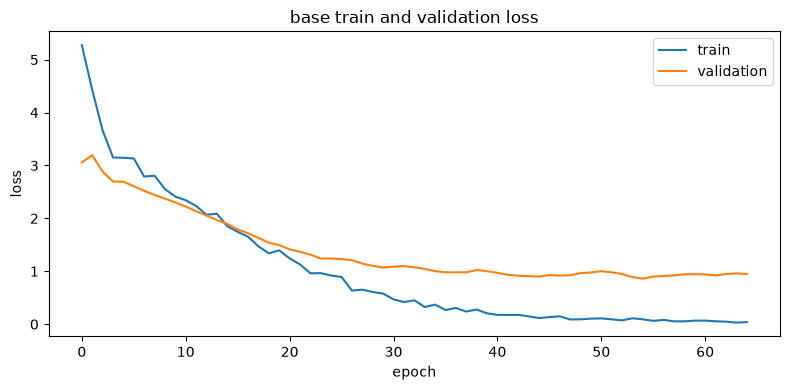

test OA=0.5778
kappa= 0.5359243962663547
each_acc= [0.32978723 0.59431818 0.50105708 0.40979381 0.87042254 0.68985177
 0.16       0.86516854 0.0257732  0.82772021 0.80662152 0.39583333
 0.216      0.87554395 0.26818675 0.1380531 ]
average_acc= 0.4983832008257048


{'num_layers': 24, 'layer_decay_rate': 0.9}
Build LayerDecayOptimizerConstructor 0.900000 - 26
Param groups = {
  "layer_25_no_decay": {
    "param_names": [
      "spat_encoder.pos_embed",
      "spat_encoder.classifier.0.bias",
      "spat_encoder.classifier.1.bias",
      "spat_encoder.classifier.2.bias",
      "spat_encoder.cls.bias",
      "spat_encoder.classifier1.0.bias",
      "spat_encoder.classifier1.1.bias",
      "spat_encoder.classifier1.2.bias",
      "spat_encoder.patch_embed.proj.bias",
      "spat_encoder.blocks.0.norm1.weight",
      "spat_encoder.blocks.0.norm1.bias",
      "spat_encoder.blocks.0.attn.qkv.bias",
      "spat_encoder.blocks.0.attn.sampling_offsets.bias",
      "spat_encoder.blocks.0.attn.proj.bias",
      "spat_encoder.blocks.0.norm2.weight",
      "spat_encoder.blocks.0.norm2.bias",
      "spat_encoder.blocks.0.mlp.fc1.bias",
      "spat_encoder.blocks.0.mlp.fc2.bias",
      "spat_encoder.blocks.1.norm1.weight",
      "spat_encoder.blocks.1.norm1.bias

/home/campus.ncl.ac.uk/c4071391/miniconda3/envs/hyperfm/lib/python3.12/site-packages/torch/_dynamo/eval_frame.py:1552: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In a future release, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


/home/campus.ncl.ac.uk/c4071391/miniconda3/envs/hyperfm/lib/python3.12/site-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


save model
model: large epoch: 0 train loss: 5.95176 val loss: 3.35232 accuracy: 0.03125


save model


... (31 outputs left out)

model: large epoch: 50 train loss: 0.04924 val loss: 0.80372 accuracy: 1.0


save model


model: large epoch: 60 train loss: 0.04234 val loss: 0.72253 accuracy: 1.0


model: large epoch: 63 train loss: 0.02509 val loss: 0.85252 accuracy: 1.0
early stopping at epoch 63


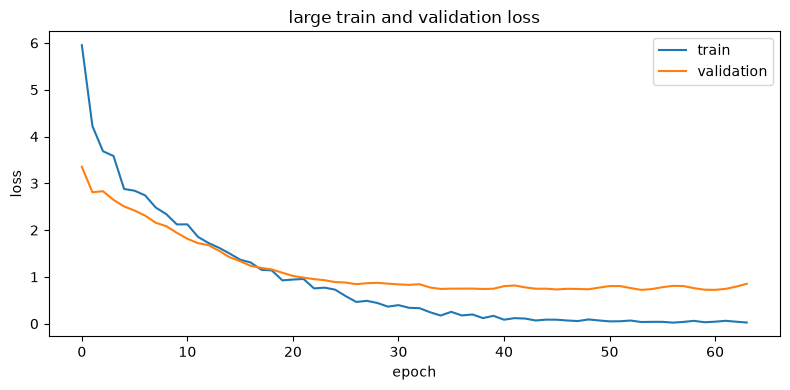

test OA=0.6544
kappa= 0.6149587209084098
each_acc= [0.29896907 0.76886035 0.53042122 0.50985222 0.93290735 0.65128755
 0.21311475 0.82238011 0.04347826 0.58281665 0.81900726 0.53058321
 0.33333333 0.83029074 0.456942   0.33854167]
average_acc= 0.541424109590196


,size,epochs,best val loss,OA,AA,kappa,time per epoch,total time,inference time,OA/time
0,base,65,0.860856,0.577780,0.498383,0.535924,6.330999,670.664421,0.293378,0.091262
1,large,64,0.721675,0.654411,0.541424,0.614959,20.297467,2079.650241,0.960287,0.032241


In [13]:
import os
import pandas as pd
import time
from datetime import datetime
import gc

gc.collect()
torch.cuda.empty_cache()

results = []
patience = 10
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
run_dir = f'{path_result}{timestamp}_hypersigma'
os.makedirs(run_dir, exist_ok=True)

for size in ['base', 'large']: # huge has memory issue
    if size == 'base':
        depth = 12
    elif size == 'large':
        depth = 24
    elif size == 'huge':
        depth = 32

    model = ss_fusion_cls.SSFusionFramework(
                img_size = img_size,
                in_channels = pca_components,
                patch_size=patch_size,
                classes = class_num+1,
                model_size=size
    )

    spat_path = f"../weights/hypersigma/spat-vit-{size}-ultra-checkpoint-1599.pth"
    spec_path = f"../weights/hypersigma/spec-vit-{size}-ultra-checkpoint-1599.pth"

    model_params = model.state_dict()
    spat_net = torch.load(spat_path, map_location=torch.device('cpu'), weights_only=False)
    for k in list(spat_net['model'].keys()):
        if 'patch_embed.proj' in k:
            del spat_net['model'][k]
    for k in list(spat_net['model'].keys()):
        if 'spat_map' in k:
            del spat_net['model'][k]
    for k in list(spat_net['model'].keys()):
        if 'spat_output_maps' in k:
            del spat_net['model'][k]
    for k in list(spat_net['model'].keys()):
        if 'pos_embed' in k:
            del spat_net['model'][k]
    spat_weights = {}
    prefix = 'spat_encoder.'
    for key, value in spat_net['model'].items():
        new_key = prefix + key
        spat_weights[new_key] = value
    per_net = torch.load(spec_path, map_location=torch.device('cpu'), weights_only=False)
    model_params = model.state_dict()
    for k in list(per_net['model'].keys()):
        if 'patch_embed.proj' in k:
            del per_net['model'][k]
        if 'spat_map' in k:
            del per_net['model'][k]
        if 'fpn1.0.weight' in k:
            del per_net['model'][k]
    spec_weights = {}
    prefix = 'spec_encoder.'
    for key, value in per_net['model'].items():
        new_key = prefix + key
        spec_weights[new_key] = value
    model_params = model.state_dict()
    for k in list(spec_weights.keys()):
        if 'spec_encoder.patch_embed' in k:
            del spec_weights[k]
    merged_params = {**spat_weights, **spec_weights}
    same_parsms = {k: v for k, v in merged_params.items() if k in model_params.keys()}
    model_params.update(same_parsms)
    model.load_state_dict(model_params)

    optim_wrapper = dict(
        optimizer=dict(
        type='AdamW', lr=6e-5, betas=(0.9, 0.999), weight_decay=0.05),
        constructor='LayerDecayOptimizerConstructor_ViT', 
        paramwise_cfg=dict(
            num_layers=depth, 
            layer_decay_rate=0.9,
            )
            )
    optimizer = build_optim_wrapper(model, optim_wrapper)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer.optimizer, max_epoch, eta_min=0, last_epoch=-1)
    criterion = nn.CrossEntropyLoss()
    model.to(device)
    best_loss = float('inf')
    epochs_without_improvement = 0
    train_losses = []
    val_losses = []
    epoch_durations = []
    total_train_time_start = time.time()
    for epoch in range(max_epoch + 1):
        start_time = time.time()
        correct = 0
        total = 0
        test_correct = 0
        test_total = 0
        _train_loss = 0
        n_train = 0
        model.train()
        for x, y in train_loader:
            if torch.cuda.is_available():
                x, y = x.to(device), y.to(device)
            y_pred = model(x)
            train_loss = criterion(y_pred, y)
            optimizer.zero_grad()
            train_loss.backward()
            optimizer.step()
            _train_loss += train_loss.item() * y.size(0)
            n_train += y.size(0)

            with torch.no_grad():
                y_pred = torch.argmax(y_pred, dim=1)
                correct = (y_pred == y).sum().item()
                total = y.size(0)

        epoch_loss = _train_loss / n_train
        epoch_accuracy = correct / total
        train_losses.append(epoch_loss)
        epoch_durations.append(time.time() - start_time)

        model.eval()
        _val_loss = 0
        n_val = 0
        with torch.no_grad():
            for x, y in val_loader:
                if torch.cuda.is_available():
                    x, y = x.to(device), y.to(device)
                val_pred = model(x)
                val_loss = criterion(val_pred, y)
                _val_loss += val_loss.item() * y.size(0)
                n_val += y.size(0)
        val_epoch_loss = _val_loss / n_val
        val_losses.append(val_epoch_loss)

        if val_epoch_loss < best_loss:
            best_loss = val_epoch_loss
            epochs_without_improvement = 0
            torch.save(model.state_dict(), path_weight + "hyper_" + size + "_model.pth")
            torch.save(optimizer.state_dict(), path_weight + "hyper_" + size + '_optimizer.pth')
            print('save model')
        else:
            epochs_without_improvement += 1

        if epoch % 10 == 0 or epochs_without_improvement >= patience:
            print(
                'model:', size,
                'epoch:', epoch,
                'train loss:', round(epoch_loss, 5),
                'val loss:', round(val_epoch_loss, 5),
                'accuracy:', round(epoch_accuracy, 5),
            )

        if epochs_without_improvement >= patience:
            print('early stopping at epoch', epoch)
            break

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(range(len(train_losses)), train_losses, label='train')
    ax.plot(range(len(val_losses)), val_losses, label='validation')
    ax.set_xlabel('epoch')
    ax.set_ylabel('loss')
    ax.set_title(f'{size} train and validation loss')
    ax.legend()
    fig.tight_layout()
    fig.savefig(f'{run_dir}/loss_{size}.png', dpi=150)
    plt.show()

    count = 0
    model.load_state_dict(torch.load(path_weight + "hyper_" + size + "_model.pth"))
    model.eval()
    with torch.no_grad():
        for x, y  in test_loader:
            if torch.cuda.is_available():
                x, y = x.to(device), y.to(device)
            inference_start = time.time()
            output = model(x)
            inference_time = time.time() - inference_start
            y_pred = torch.argmax(output, dim=1)
            test_correct += (y_pred == y).sum().item()
            test_total += y.size(0)

            if count == 0:
                y_pred_test =  y_pred.cpu().numpy()
                y_gt_test = y.cpu().numpy()
                count = 1
            else:
                y_pred_test = np.concatenate( (y_pred_test, y_pred.cpu().numpy()) )
                y_gt_test = np.concatenate( (y_gt_test, y.cpu().numpy()) )

    overall_acc = metrics.accuracy_score(y_pred_test, y_gt_test)
    confusion_matrix = metrics.confusion_matrix(y_pred_test, y_gt_test)
    each_acc, average_acc = utils.aa_and_each_accuracy(confusion_matrix)
    kappa = metrics.cohen_kappa_score(y_pred_test, y_gt_test)
    OA_HybirdSN = test_correct / test_total
    print("test OA={:.4f}".format(overall_acc))
    print('kappa=',kappa)
    print('each_acc=',each_acc)
    print('average_acc=',average_acc)

    time_per_epoch = float(np.mean(epoch_durations))
    epochs_run = len(epoch_durations)
    total_time = time.time() - total_train_time_start

    results.append({
        "size": size, 
        "epochs": epochs_run,
        "best val loss": best_loss,
        "OA": overall_acc,
        "AA": average_acc,
        "kappa": kappa,
        "time per epoch": time_per_epoch,
        "total time": total_time,
        "inference time": inference_time,
        "OA/time": overall_acc / time_per_epoch,
    })

    del model, optimizer, scheduler, spat_net, per_net
    gc.collect()
    torch.cuda.empty_cache()

# One row per seed; the summary is mean and std (pandas default ddof=1) across seeds.
df = pd.DataFrame(results)
df.to_csv(f'{run_dir}/benchmarking.csv')
display(df)


In [14]:
df


,size,epochs,best val loss,OA,AA,kappa,time per epoch,total time,inference time,OA/time
0,base,65,0.860856,0.577780,0.498383,0.535924,6.330999,670.664421,0.293378,0.091262
1,large,64,0.721675,0.654411,0.541424,0.614959,20.297467,2079.650241,0.960287,0.032241
